In [7]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential()
model.add(Input(shape=(4,)))
model.add(Dense(50, activation="sigmoid"))
model.add(Dense(30, activation="sigmoid"))
model.add(Dense(3, activation="softmax"))
model.summary()


W0000 00:00:1791591992.933735   28158 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791591992.953371   28158 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791591993.062601   28158 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 29802 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5090, pci bus id: 0000:c2:00.0, compute capability: 12.0a


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │           250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         1,530 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            93 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,873 (7.32 KB)

 Trainable params: 1,873 (7.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [12]:
from sklearn import datasets
iris = datasets.load_iris()
x, y = iris.data, iris.target


In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1)

In [20]:
# model.fit(X_train, y_train, epochs=200)
model.fit(X_train, y_train, validation_split=0.1, epochs=200)
# model.fit(X_train, y_train, validation_data=(X_train, y_train) epochs=200)

Epoch 1/200


I0000 00:00:1791592656.937217   29927 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8039__.13


1/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.9688 - loss: 0.1234

I0000 00:00:1791592657.795999   29928 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8039__.13


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9681 - loss: 0.1319 - val_accuracy: 0.9091 - val_loss: 0.2251
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9787 - loss: 0.1295 - val_accuracy: 0.9091 - val_loss: 0.2200
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9787 - loss: 0.1280 - val_accuracy: 0.9091 - val_loss: 0.2203
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9787 - loss: 0.1257 - val_accuracy: 0.9091 - val_loss: 0.2164
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9787 - loss: 0.1241 - val_accuracy: 0.9091 - val_loss: 0.2143
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9787 - loss: 0.1225 - val_accuracy: 0.9091 - val_loss: 0.2129
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9787 - loss: 0.1211 - val_accuracy: 0.9091 - val_loss: 0.2104
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9787 - loss: 0.1195 - val_accuracy: 0.9091 - val_loss: 0.2104
Epoch 

In [21]:
model.evaluate(X_test, y_test) # loss, acurracy

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 902ms/step - accuracy: 1.0000 - loss: 0.0267


[0.026692941784858704, 1.0]

In [22]:
model.save('iris_model.keras')

# 와인 데이터

In [ ]:
# 데이터를 불러오고 독립변수와 종속 변수를 분리함
import pandas as pd

redwine = pd.read_csv('winequality-red.csv', sep=';')
X, y = redwine.iloc[:, :-1], redwine.iloc[:, -1]

In [24]:
# 훈련 데이터셋과 평가 데이터셋으로 나눔

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y)

In [27]:
# 모델 정의
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(11,)),
    Dense(100, activation='sigmoid'),
    Dense(200, activation='relu'),
    Dense(50, activation='tanh'),
    Dense(10, activation='softmax'),
])

In [28]:
# 훈련 정의
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

In [29]:
# 학습
history = model.fit(X_train, y_train, batch_size=200, epochs=300)

Epoch 1/300


I0000 00:00:1791596416.840964   29929 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17929__.14
I0000 00:00:1791596417.004510   29929 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791596417.449460  273994 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791596417.475474  273946 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791596418.118051   29929 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a goo

1/6 ━━━━━━━━━━━━━━━━━━━━ 27s 5s/step - accuracy: 0.0650 - loss: 2.3474

I0000 00:00:1791596420.676753   29928 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17929__.14
I0000 00:00:1791596421.243210   29928 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791596421.635577  274306 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791596421.656751  274344 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791596421.864795   29928 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a goo

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 732ms/step - accuracy: 0.3378 - loss: 1.6565
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4529 - loss: 1.2411 
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4529 - loss: 1.1920 
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4862 - loss: 1.1758 
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4762 - loss: 1.1570 
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4871 - loss: 1.1495 
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4921 - loss: 1.1425 
Epoch 8/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4812 - loss: 1.1360 
Epoch 9/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4821 - loss: 1.1294 
Epoch 10/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4954 - loss: 1.1272 
Epoch 11/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4904 - loss: 1.1250 
Epoch 12/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4962 - loss: 1.1208 


In [30]:
#모델 평가
model.evaluate(X_test, y_test)

I0000 00:00:1791596740.131151   29930 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791596740.355202  391754 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



 1/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5938 - loss: 1.0135

I0000 00:00:1791596741.261007  392005 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1791596741.487373   29928 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.5725 - loss: 1.0187


[1.018704891204834, 0.5724999904632568]

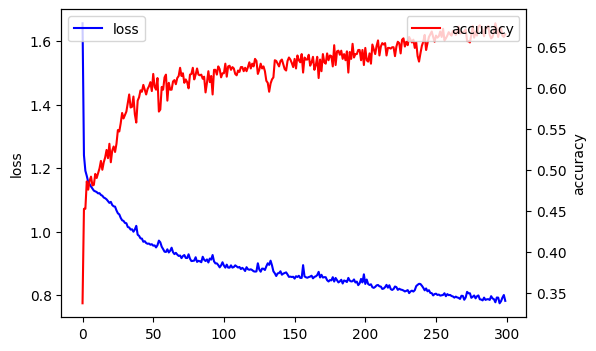

In [41]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(6,4))
ax1.plot(history.history['loss'], 'b-', label='loss')
ax1.set_ylabel('loss')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(history.history['accuracy'], 'r-', label='accuracy')
ax2.set_ylabel('accuracy')
ax2.legend(loc='upper right')
plt.show()

In [40]:
# 예측한 결과 처음 5개 출력해보기
import numpy as np
pred = model.predict(X_test)
print(np.argmax(pred[:5], axis=1))
print(y_test[:5].values)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
[6 5 6 5 5]
[6 5 8 4 5]


# 6. 콜백 이용하기

In [32]:
import pandas as pd

redwine = pd.read_csv("winequality-red.csv", sep=";")
X, y = redwine.iloc[:, :-1], redwine.iloc[:, -1]

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    stratify=y, # stratified sampling
                                                    test_size=0.25, # 75:25 split by default
                                                    random_state=1) 

In [34]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid'))
model.add(Dense(200, activation='relu'))
model.add(Dense(50, activation='tanh'))
model.add(Dense(10, activation='softmax'))
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,960 (124.84 KB)

 Trainable params: 31,960 (124.84 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [36]:
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard

checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True)
tensorboard = TensorBoard(log_dir='logs', histogram_freq=1, embeddings_freq=1)

In [37]:
model.fit(X_train, y_train,
          batch_size=200, epochs=300, 
          callbacks=[checkpoint, tensorboard],
          validation_data=(X_test, y_test))

Epoch 1/300


I0000 00:00:1791605361.038348   29928 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_30600__.14


1/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3150 - loss: 2.0315

I0000 00:00:1791605362.451628   29930 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_30600__.14


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 445ms/step - accuracy: 0.4170 - loss: 1.5403 - val_accuracy: 0.4425 - val_loss: 1.2367
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4912 - loss: 1.2025 - val_accuracy: 0.4900 - val_loss: 1.1679
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5054 - loss: 1.1696 - val_accuracy: 0.4925 - val_loss: 1.1485
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5004 - loss: 1.1507 - val_accuracy: 0.5100 - val_loss: 1.1358
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4962 - loss: 1.1411 - val_accuracy: 0.4975 - val_loss: 1.1220
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5029 - loss: 1.1360 - val_accuracy: 0.5100 - val_loss: 1.1146
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4996 - loss: 1.1397 - val_accuracy: 0.5000 - val_loss: 1.1098
Epoch 8/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4979 - loss: 1.1336 - val_accuracy: 0.4950 - val_loss: 1.1083
Epo

In [38]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(loss, accuracy)

0.9356293678283691 0.6225000023841858


In [39]:
from tensorflow.keras.models import load_model
best_model = load_model('best_model.keras')

loss, accuracy = best_model.evaluate(X_test, y_test)
print(f'loss: {loss}, accuracy: {accuracy}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.6325 - loss: 0.9229
loss: 0.9229253530502319, accuracy: 0.6324999928474426


# 7. 인공신경망 모델 최적화

In [42]:
# 기본모델

In [43]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid'))
model.add(Dense(200, activation='relu'))
model.add(Dense(50, activation='tanh'))
model.add(Dense(10, activation='softmax'))
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,960 (124.84 KB)

 Trainable params: 31,960 (124.84 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# 드롭아웃 적용

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid'))
model.add(Dropout(0.2))
model.add(Dense(200, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(50, activation='tanh'))
model.add(Dropout(0.1))
model.add(Dense(10, activation='softmax'))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,960 (124.84 KB)

 Trainable params: 31,960 (124.84 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# 활성화 함수 적용

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, ELU, PReLU, Activation
from tensorflow.keras.activations import softmax

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid')) # 문자열로 지정 
model.add(Dense(200, activation=PReLU()))   # 클래스로 객체를 생성해서 지정
model.add(Dense(50))
model.add(Activation(ELU(alpha=0.1)))       # Activation 레이어 추가 지정
model.add(Dense(10, activation=softmax))    # 함수 이름으로 지정
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,960 (124.84 KB)

 Trainable params: 31,960 (124.84 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
# 가중치 초기화

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.initializers import RandomNormal

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid', kernel_initializer=RandomNormal(stddev=0.05))) # 평균 0, 표준편차 0.05
model.add(Dense(200, activation='relu', kernel_initializer='glorot_uniform')) # 기본값은 Glorot uniform
model.add(Dense(50, activation='tanh', kernel_initializer='he_normal')) # He normal
model.add(Dense(10, activation='softmax')) # 가중치 초기값은 glorot_uniform
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_23 (Dense)                │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,960 (124.84 KB)

 Trainable params: 31,960 (124.84 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# 배치 정규화

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, BatchNormalization

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(100, activation='sigmoid'))
model.add(BatchNormalization())
model.add(Dense(200, activation='relu'))
model.add(BatchNormalization())
model.add(Dense(50, activation='tanh'))
model.add(BatchNormalization())
model.add(Dense(10, activation='softmax'))
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 200)            │           800 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 50)             │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50)             │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,360 (130.31 KB)

 Trainable params: 32,660 (127.58 KB)

 Non-trainable params: 700 (2.73 KB)

In [48]:
# 손실함수 및 옵티마이저

model.compile(loss='sparse_categorical_crossentropy', 
              optimizer='adam')

In [ ]:
import tensorflow
model.compile(loss='sparse_categorical_crossentropy', optimizer=tensorflow.keras.optimizers.Adam())